# EdgeViT on the Chest CT-Scan Images dataset (lung cancer, 4 classes)

Implementation of **EdgeViTs: Competing Light-weight CNNs on Mobile Devices with Vision Transformers** (Pan et al., ECCV 2022) in PyTorch, trained **from scratch**: 4-stage pyramid of Local-Global-Local (LGL) bottlenecks (local aggregation, global sparse attention on delegate tokens with sample rates 4/2/2/1, local propagation), variants XXS / XS / S. Model code is the public implementation github.com/1hunters/EdgeViT.

Outputs: train / val / test loss, accuracy, F1, precision, recall curves; confusion matrices; classification report; ROC; parameters and forward/backward FLOPs.

In [1]:
!pip install -q kagglehub seaborn scikit-learn tqdm pillow

## 1. Config

In [2]:
import os, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report

# ---------------- model ----------------
VARIANT      = "XXS"     # XXS / XS / S, Table 1 of the paper
IMG_SIZE     = 224
# ---------------- training ----------------
BATCH_SIZE   = 32
EPOCHS       = 50
LR           = 1e-3      # paper: 1e-3 (AdamW)
WEIGHT_DECAY = 0.025     # paper: 2.5e-2
SEED         = 42

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # small rotation / shift / scale + brightness-contrast (no flips)
USE_CLASS_WEIGHTS = False   # class-weighted cross-entropy

AVG = "macro"             # averaging for precision / recall / F1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = device
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data

[Chest CT-Scan images Dataset (Kaggle, mohamedhanyyy)](https://www.kaggle.com/datasets/mohamedhanyyy/chest-ctscan-images): 2D CT slices in 4 classes (adenocarcinoma, large cell carcinoma, squamous cell carcinoma, normal) with ready-made train / valid / test folders. In a Kaggle notebook, add the dataset as input; elsewhere `kagglehub` needs your Kaggle API token.

In [3]:
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
# os.environ["KAGGLE_USERNAME"] = "your_username"   # only if you do not have ~/.kaggle/kaggle.json
# os.environ["KAGGLE_KEY"]      = "your_key"
KAGGLE_PATH = "/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data"   # layout: Data/{train,valid,test}
if os.path.exists(KAGGLE_PATH):
    DATA_DIR = KAGGLE_PATH
else:                                   # other layout / not on Kaggle: search, or download with kagglehub
    root = "/kaggle/input"
    if not os.path.exists(root):
        import kagglehub
        root = kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images")
    DATA_DIR = next((dp for dp, dn, _ in os.walk(root, followlinks=True) if {"train", "valid", "test"} <= set(dn)), None)
    if DATA_DIR is None:
        for dp, dn, _ in os.walk(root, followlinks=True):           # show what is really there
            print(dp, dn[:6])
        raise FileNotFoundError("no folder with train/valid/test found under " + root)
print("DATA_DIR:", DATA_DIR)

CLASS_NAMES = ["adenocarcinoma", "large.cell.carcinoma", "normal", "squamous.cell.carcinoma"]; NUM_CLASSES = 4
def class_index(folder):      # folder names differ between splits (train/valid long names, test short names)
    for i, n in enumerate(CLASS_NAMES):
        if folder.lower().startswith(n): return i
    raise ValueError(folder)

def load_split(split):
    base = os.path.join(DATA_DIR, split); xs, ys = [], []
    items = [(os.path.join(base, d, f), class_index(d)) for d in sorted(os.listdir(base)) for f in sorted(os.listdir(os.path.join(base, d)))
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    def one(p): return np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
    with ThreadPoolExecutor(8) as ex: xs = list(tqdm(ex.map(one, [p for p, _ in items]), total=len(items), desc=split))
    return np.stack(xs), np.array([y for _, y in items])

Xtr, Ytr = load_split("train"); Xva, Yva = load_split("valid"); Xte, Yte = load_split("test")
print(Xtr.shape, Xva.shape, Xte.shape)
for n, y in [("train", Ytr), ("val", Yva), ("test", Yte)]:
    print(f"{n:5s}", dict(zip(CLASS_NAMES, np.bincount(y, minlength=4))))

DATA_DIR: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data


train:   0%|          | 0/613 [00:00<?, ?it/s]

valid:   0%|          | 0/72 [00:00<?, ?it/s]

test:   0%|          | 0/315 [00:00<?, ?it/s]

(613, 224, 224) (72, 224, 224) (315, 224, 224)
train {'adenocarcinoma': np.int64(195), 'large.cell.carcinoma': np.int64(115), 'normal': np.int64(148), 'squamous.cell.carcinoma': np.int64(155)}
val   {'adenocarcinoma': np.int64(23), 'large.cell.carcinoma': np.int64(21), 'normal': np.int64(13), 'squamous.cell.carcinoma': np.int64(15)}
test  {'adenocarcinoma': np.int64(120), 'large.cell.carcinoma': np.int64(51), 'normal': np.int64(54), 'squamous.cell.carcinoma': np.int64(90)}


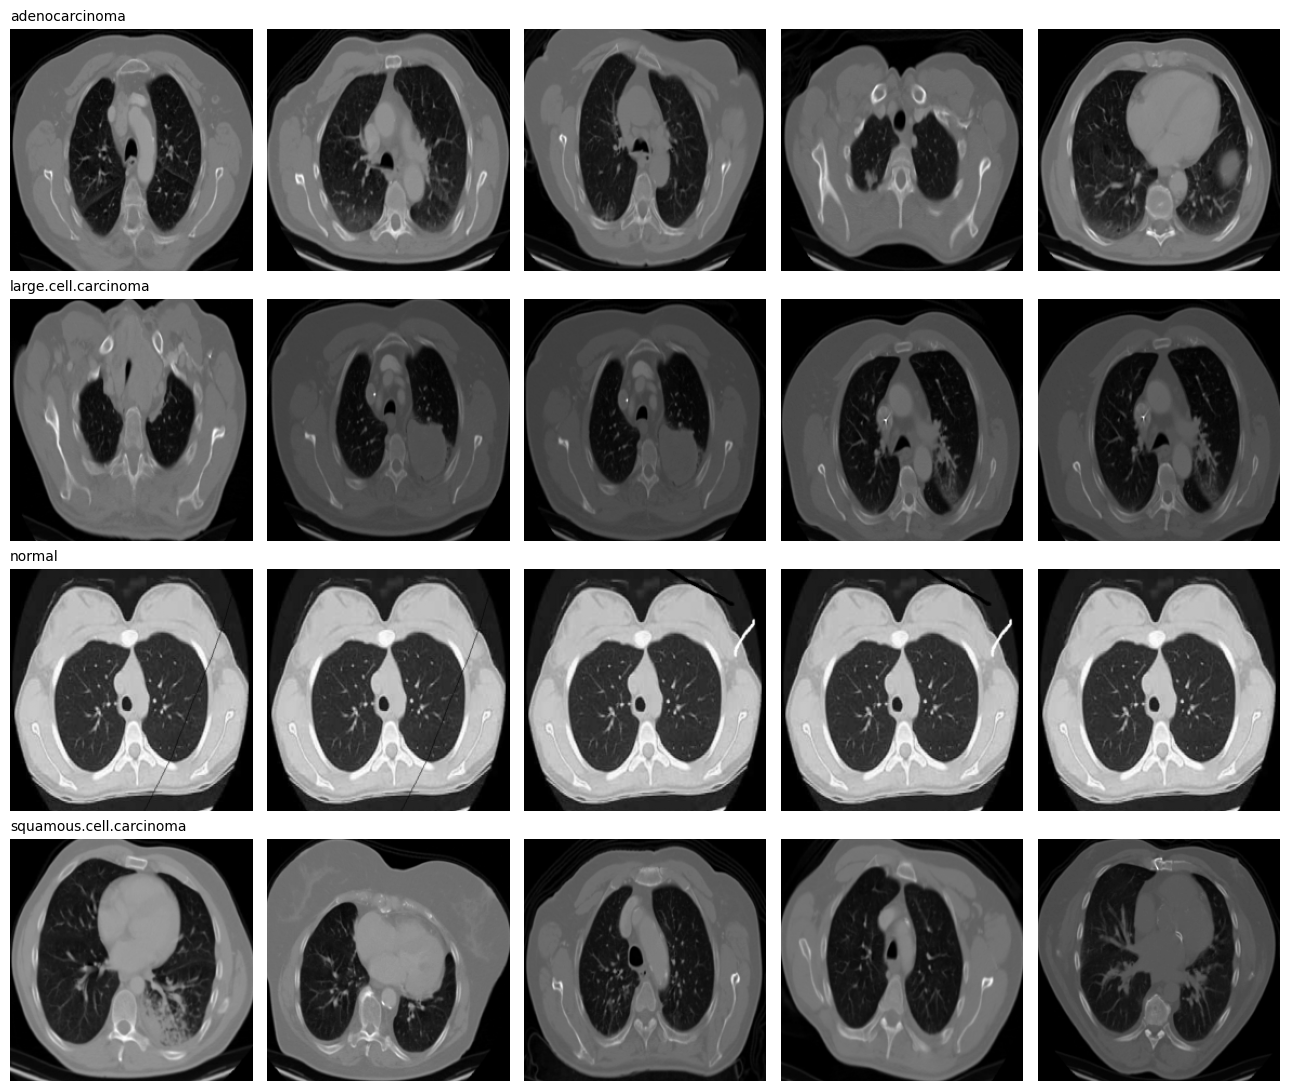

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(4, 5, figsize=(13, 11))
for cls in range(4):
    for a, i in zip(ax[cls], np.where(Ytr == cls)[0][:5]):
        a.imshow(Xtr[i], cmap="gray"); a.axis("off")
    ax[cls][0].set_title(CLASS_NAMES[cls], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3. EdgeViT model

In [5]:
# EdgeViT model code taken from the public implementation https://github.com/1hunters/EdgeViT (edgevit.py), unmodified except for the
# attention scale/fp32 fix below and the added `in_chans` argument (1-channel grayscale input) and the `make_edgevit` helper below.
import torch
import torch.nn as nn

edgevit_configs = {
    'XXS': {
        'channels': (36, 72, 144, 288),
        'blocks': (1, 1, 3, 2),
        'heads': (1, 2, 4, 8)
    }
    ,
    'XS': {
        'channels': (48, 96, 240, 384),
        'blocks': (1, 1, 2, 2),
        'heads': (1, 2, 4, 8)
    }
    ,
    'S': {
        'channels': (48, 96, 240, 384),
        'blocks': (1, 2, 3, 2),
        'heads': (1, 2, 4, 8)
    }
}

HYPERPARAMETERS = {
    'r': (4, 2, 2, 1)
}


class Residual(nn.Module):
    def __init__(self, module):
        super().__init__()
        self.module = module
    
    def forward(self, x):
        return x + self.module(x)


class ConditionalPositionalEncoding(nn.Sequential):
    def __init__(self, channels):
        super().__init__()
        self.add_module('conditional_ositional_encoding', nn.Conv2d(channels, channels, kernel_size=3, padding=1, groups=channels, bias=False))


class MLP(nn.Sequential):
    def __init__(self, channels):
        super().__init__()
        expansion = 4
        self.add_module('mlp_layer_0', nn.Conv2d(channels, channels*expansion, kernel_size=1, bias=False))
        self.add_module('mlp_act', nn.GELU())
        self.add_module('mlp_layer_1', nn.Conv2d(channels*expansion, channels, kernel_size=1, bias=False))


class LocalAggModule(nn.Sequential):
    def __init__(self, channels):
        super().__init__()
        self.add_module('pointwise_prenorm_0', nn.BatchNorm2d(channels))
        self.add_module('pointwise_conv_0', nn.Conv2d(channels, channels, kernel_size=1, bias=False))
        self.add_module('depthwise_conv', nn.Conv2d(channels, channels, padding=1, kernel_size=3, groups=channels, bias=False))
        self.add_module('pointwise_prenorm_1', nn.BatchNorm2d(channels))
        self.add_module('pointwise_conv_1', nn.Conv2d(channels, channels, kernel_size=1, bias=False))


class GlobalSparseAttetionModule(nn.Module):
    def __init__(self, channels, r, heads):
        super().__init__()
        self.head_dim = channels//heads
        self.scale = self.head_dim**-0.5
        self.num_heads = heads

        self.sparse_sampler = nn.AvgPool2d(kernel_size=1, stride=r)
        self.norm = nn.GroupNorm(num_groups=1, num_channels=channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1, bias=False)
        self.local_prop = nn.ConvTranspose2d(channels, channels, kernel_size=r, stride=r, groups=channels)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1, bias=False)
    
    def forward(self, x):
        x = self.sparse_sampler(x)
        B, C, H, W = x.shape
        q, k, v = self.qkv(x).view(B, self.num_heads, -1, H*W).split([self.head_dim, self.head_dim, self.head_dim], dim=2)
        # NaN fix: the public code omits the 1/sqrt(d) scale and runs this in fp16 under AMP -> logits overflow. Scale + fp32 softmax.
        with torch.autocast(device_type=x.device.type, enabled=False):
            q, k, v = q.float(), k.float(), v.float()
            attn = ((q.transpose(-2, -1) @ k) * self.scale).softmax(-1)
            x = (v @ attn.transpose(-2, -1)).view(B, -1, H, W)
        x = self.local_prop(x.to(self.proj.weight.dtype) if x.dtype != self.proj.weight.dtype else x)
        x = self.norm(x)
        x = self.proj(x)

        return x


class ConvDownsampling(nn.Sequential):
    def __init__(self, inp, oup, r, bias=False):
        super().__init__()
        self.add_module('downsampling_conv', nn.Conv2d(inp, oup, kernel_size=r, stride=r, bias=bias))
        self.add_module('downsampling_norm', nn.GroupNorm(num_groups=1, num_channels=oup))


class EdgeViT(nn.Module):
    def __init__(self, channels, blocks, heads, r=[4, 2, 2, 1], num_classes=1000, distillation=False, in_chans=3):
        super().__init__()
        self.distillation = distillation
        
        l = []
        in_channels = in_chans
        for stage_id, (num_channels, num_blocks, num_heads, sample_ratio) in enumerate(zip(channels, blocks, heads, r)):
            l.append(ConvDownsampling(inp=in_channels, oup=num_channels, r=4 if stage_id == 0 else 2))

            for _ in range(num_blocks):
                l.append(Residual(ConditionalPositionalEncoding(num_channels)))
                l.append(Residual(LocalAggModule(num_channels)))
                l.append(Residual(MLP(num_channels)))
                l.append(Residual(ConditionalPositionalEncoding(num_channels)))
                l.append(Residual(GlobalSparseAttetionModule(channels=num_channels, r=sample_ratio, heads=num_heads)))
                l.append(Residual(MLP(num_channels)))
            
            in_channels = num_channels
        
        self.main_body = nn.Sequential(*l)
        self.pooling = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Linear(in_channels, num_classes, bias=True)

        if self.distillation:
            self.dist_classifier = nn.Linear(in_channels, num_classes, bias=True)
    
    def forward(self, x):
        x = self.main_body(x)
        x = self.pooling(x).flatten(1)

        if self.distillation:
            x = self.classifier(x), self.dist_classifier(x)

            if not self.training:
                x = 1/2 * (x[0] + x[1])
        else:
            x = self.classifier(x)
        
        return x


def make_edgevit(variant, in_chans, num_classes):
    return EdgeViT(**edgevit_configs[variant], in_chans=in_chans, num_classes=num_classes)

## 4. Training utilities

In [6]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).long()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, translation +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        dev = DEVICE
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(dev, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(dev, non_blocking=True)


def metrics(y, p, avg):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def auc_score(y, prob):
    try:
        if prob.shape[1] == 2:
            return roc_auc_score(y, prob[:, 1])
        return roc_auc_score(y, prob, multi_class="ovr", average="macro")
    except ValueError:
        return float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, n, ys, ps, pr = 0.0, 0, [], [], []
    for x, y in loader:
        out = model(x).float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); pr.append(out.softmax(1).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(pr).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device, avg, epochs=30, lr=1e-3,
        weight_decay=0.025, warmup=3, use_amp=True, ckpt="best_efficientvit.pt"):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warmup if e < warmup
                                              else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
        tr = (tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vl, vy, vp, _ = evaluate(model, val_loader, criterion)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion)          # monitoring only, never used for selection
        for name, (l, y, p) in [("train", tr), ("val", (vl, vy, vp)), ("test", (sl, sy, sp))]:
            hist[f"{name}_loss"].append(l)
            for k, v in metrics(y, p, avg).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        improved = hist["val_f1"][-1] > best_f1
        if improved:
            best_f1 = hist["val_f1"][-1]; best_state = copy.deepcopy(model.state_dict()); torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | loss tr {tr[0]:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else ""))
    model.load_state_dict(best_state)
    return hist

In [7]:
set_seed(SEED)
cw = None
if USE_CLASS_WEIGHTS:
    cnt = np.bincount(Ytr, minlength=NUM_CLASSES); cw = torch.tensor(cnt.sum() / (NUM_CLASSES * cnt), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=cw)

train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

model = make_edgevit(VARIANT, in_chans=1, num_classes=NUM_CLASSES).to(device)
print("output shape:", model(torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)).shape)

output shape: torch.Size([2, 4])


## 5. Parameters and FLOPs (forward / backward, per image and per batch)

In [8]:
import pandas as pd
from torch.utils.flop_counter import FlopCounterMode

def measure_flops(model, batch_size):
    """Forward and backward FLOPs of one training step (1 multiply-add = 2 FLOPs; matmul/conv/attention only)."""
    model.train(); model.zero_grad(set_to_none=True)
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=device)
    with FlopCounterMode(display=False) as fc:
        out = model(x); fwd = fc.get_total_flops()
        out.float().sum().backward(); tot = fc.get_total_flops()
    model.zero_grad(set_to_none=True)
    return fwd, tot - fwd

def complexity_report(model):
    total = sum(p.numel() for p in model.parameters()); trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fb, bb = measure_flops(model, BATCH_SIZE)
    f2, b2 = measure_flops(model, 2)               # per image = batch of 2 / 2 (BatchNorm needs >1 sample in train mode)
    f1, b1 = f2 / 2, b2 / 2
    fmt = lambda v: f"{v/1e6:.2f} M" if v < 1e9 else f"{v/1e9:.3f} G"
    rows = {"Total parameters": total, "Trainable parameters": trainable, "Non-trainable parameters": total - trainable,
            "Forward FLOPs / image": f1, "Backward FLOPs / image": b1, "Forward+Backward FLOPs / image": f1 + b1,
            f"Forward FLOPs / batch ({BATCH_SIZE})": fb, f"Backward FLOPs / batch ({BATCH_SIZE})": bb,
            f"Forward+Backward FLOPs / batch ({BATCH_SIZE})": fb + bb, "Forward MAdds / image (FLOPs/2, paper unit)": f1 / 2}
    df = pd.DataFrame({"value": rows}); df["readable"] = [fmt(v) for v in df["value"]]
    print(f"Input 1 x {IMG_SIZE} x {IMG_SIZE} | batch {BATCH_SIZE}"); display(df); df.to_csv("model_complexity.csv")

complexity_report(model)

Input 1 x 224 x 224 | batch 32


,value,readable
Total parameters,5.422324e+06,5.42 M
Trainable parameters,5.422324e+06,5.42 M
Non-trainable parameters,0.000000e+00,0.00 M
Forward FLOPs / image,1.250241e+09,1.250 G
Backward FLOPs / image,4.074252e+09,4.074 G
Forward+Backward FLOPs / image,5.324493e+09,5.324 G
Forward FLOPs / batch (32),4.000771e+10,40.008 G
Backward FLOPs / batch (32),1.303761e+11,130.376 G
Forward+Backward FLOPs / batch (32),1.703838e+11,170.384 G
"Forward MAdds / image (FLOPs/2, paper unit)",6.251204e+08,625.12 M


## 6. Training

AdamW, linear warm-up + cosine decay, mixed precision on GPU. Test metrics are logged each epoch **only** for the curves; the best checkpoint is chosen by **validation F1**.

In [9]:
set_seed(SEED)
model = make_edgevit(VARIANT, in_chans=1, num_classes=NUM_CLASSES).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device, AVG,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, ckpt="best_edgevit.pt")

Ep 01/50 |   6.0s | loss tr 1.7120 val 1.3314 test 1.1516 | F1 tr 0.396 val 0.276 test 0.346  *best*
Ep 02/50 |   1.5s | loss tr 0.8618 val 1.9649 test 1.2572 | F1 tr 0.631 val 0.265 test 0.440
Ep 03/50 |   1.5s | loss tr 0.7825 val 1.6246 test 2.4678 | F1 tr 0.704 val 0.315 test 0.254  *best*
Ep 04/50 |   1.5s | loss tr 0.6020 val 1.1019 test 1.3996 | F1 tr 0.786 val 0.707 test 0.488  *best*
Ep 05/50 |   1.5s | loss tr 0.4079 val 1.0698 test 1.3584 | F1 tr 0.855 val 0.633 test 0.500
Ep 06/50 |   1.5s | loss tr 0.4508 val 1.2112 test 1.6629 | F1 tr 0.815 val 0.621 test 0.446
Ep 07/50 |   1.5s | loss tr 0.2916 val 1.6801 test 1.6624 | F1 tr 0.883 val 0.602 test 0.450
Ep 08/50 |   1.5s | loss tr 0.2859 val 0.8600 test 1.2202 | F1 tr 0.901 val 0.754 test 0.500  *best*
Ep 09/50 |   1.5s | loss tr 0.2321 val 1.5916 test 1.9803 | F1 tr 0.926 val 0.675 test 0.453
Ep 10/50 |   1.5s | loss tr 0.2030 val 1.8685 test 2.0423 | F1 tr 0.933 val 0.568 test 0.405
Ep 11/50 |   1.5s | loss tr 0.1987 val

## 7. Curves

In [10]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc
from sklearn.preprocessing import label_binarize

def plot_history(h, avg_name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({avg_name})"),
                              ("precision", f"Precision ({avg_name})"), ("recall", f"Recall ({avg_name})")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate"); ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    n = len(names); cm = confusion_matrix(y, p, labels=range(n)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    w = max(11, 1.6 * n * 2)
    fig, ax = plt.subplots(1, 2, figsize=(w, max(4.5, 0.9 * n + 2.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0]); ax[0].set_title(f"{title} - counts")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, fname="roc_curves.png"):
    plt.figure(figsize=(6.5, 5.5))
    if len(names) == 2:
        fpr, tpr, _ = roc_curve(y, prob[:, 1]); plt.plot(fpr, tpr, lw=2, label=f"{names[1]} (AUC {sk_auc(fpr, tpr):.3f})")
    else:
        yb = label_binarize(y, classes=range(len(names)))
        for i, n in enumerate(names):
            fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC (test)"); plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

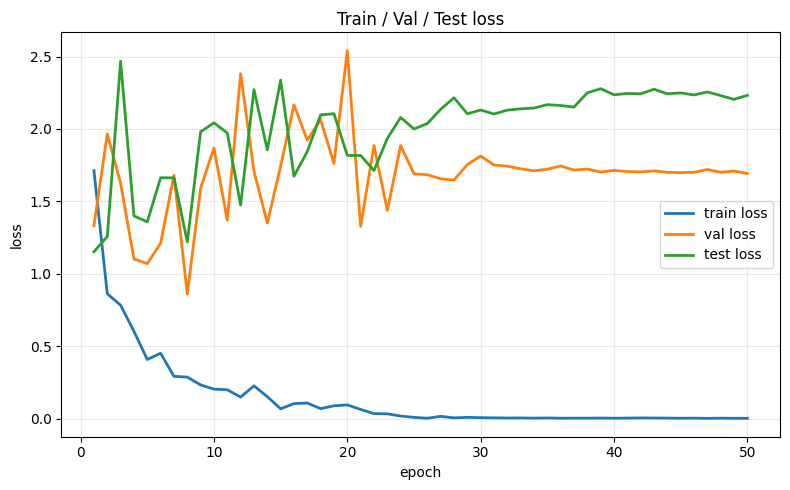

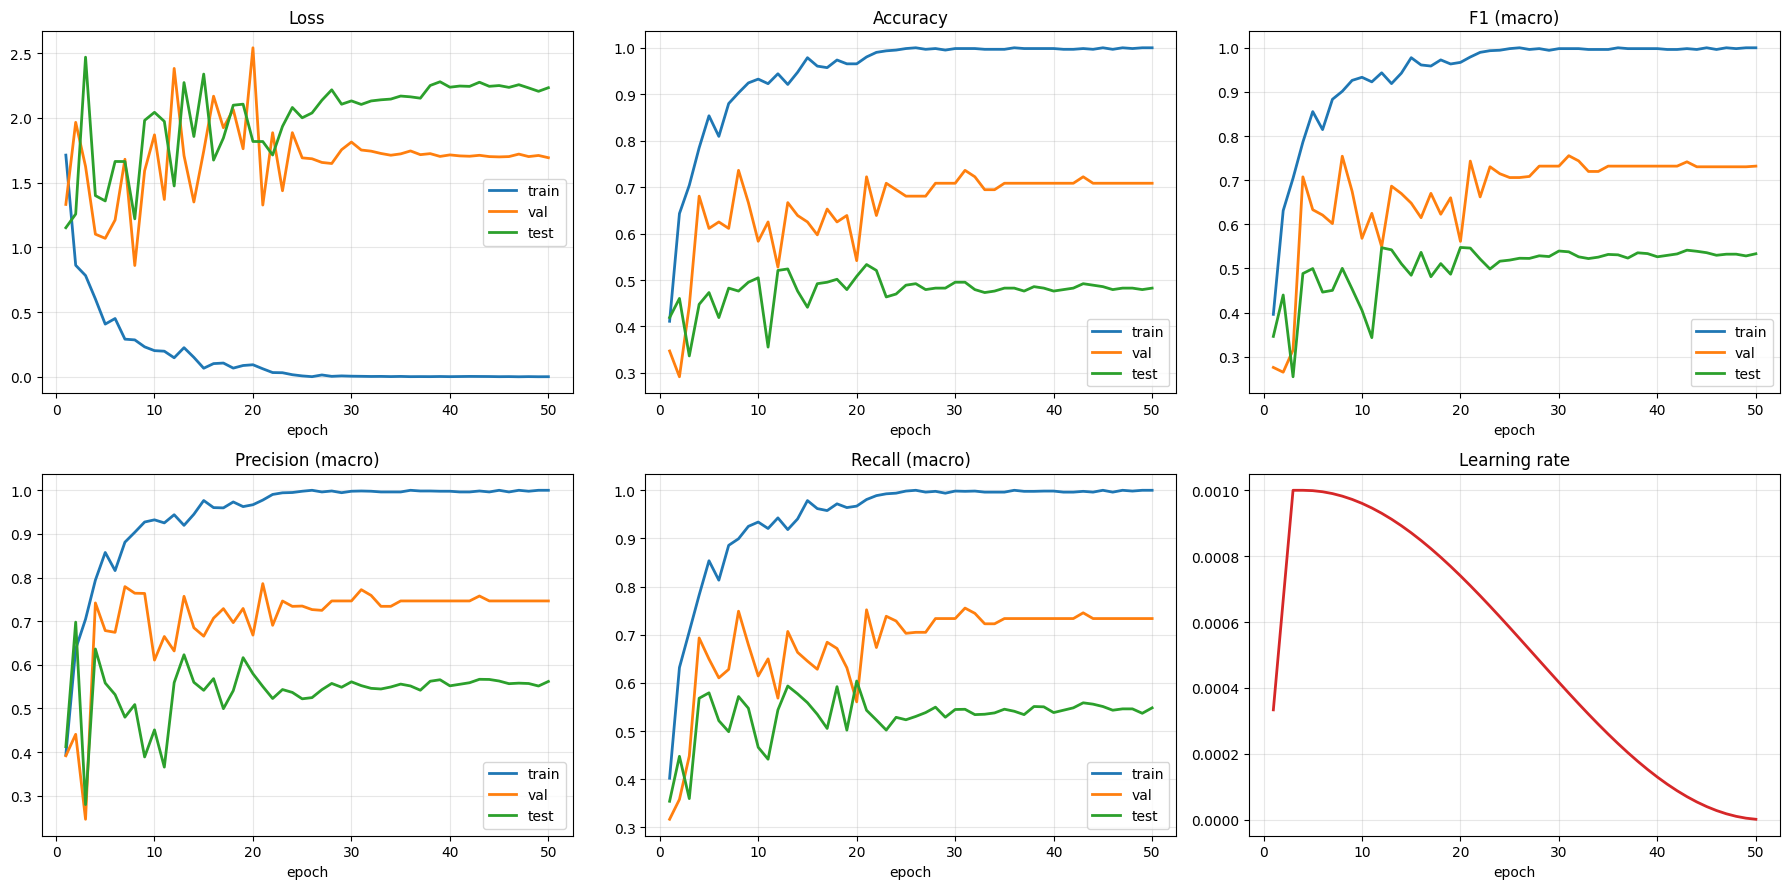

In [11]:
plot_loss_only(history)
plot_history(history, AVG)

## 8. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
res = {n: evaluate(model, l, criterion) for n, l in [("val", val_loader), ("test", test_loader)]}
rows = []
for n, (loss, y, p, prob) in res.items():
    m = metrics(y, p, AVG); m["loss"] = loss; m["auc"] = auc_score(y, prob); rows.append(pd.Series(m, name=n))
print(f"precision / recall / F1 = {AVG}-averaged")
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))
_, ytest, ptest, probtest = res["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

precision / recall / F1 = macro-averaged
        loss     acc  precision  recall      f1     auc
val   1.7514  0.7361     0.7723  0.7554  0.7554  0.8938
test  2.1032  0.4952     0.5524  0.5452  0.5376  0.7720

Test classification report
                         precision    recall  f1-score   support

         adenocarcinoma     0.4831    0.3583    0.4115       120
   large.cell.carcinoma     0.2526    0.4706    0.3288        51
                 normal     0.9800    0.9074    0.9423        54
squamous.cell.carcinoma     0.4938    0.4444    0.4678        90

               accuracy                         0.4952       315
              macro avg     0.5524    0.5452    0.5376       315
           weighted avg     0.5341    0.4952    0.5052       315



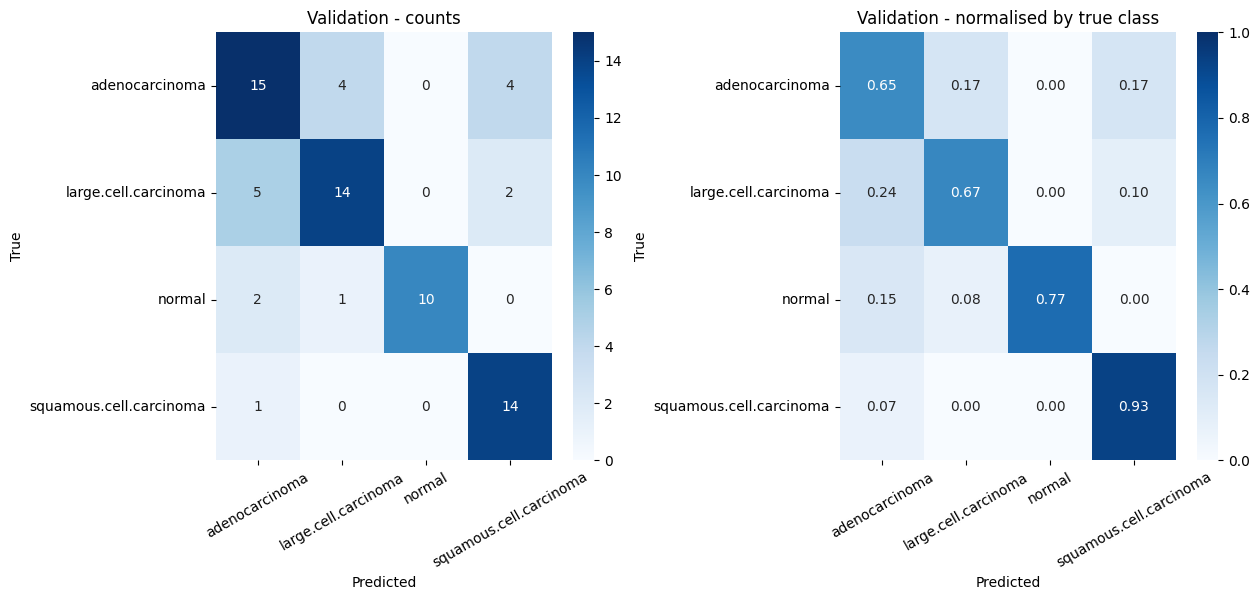

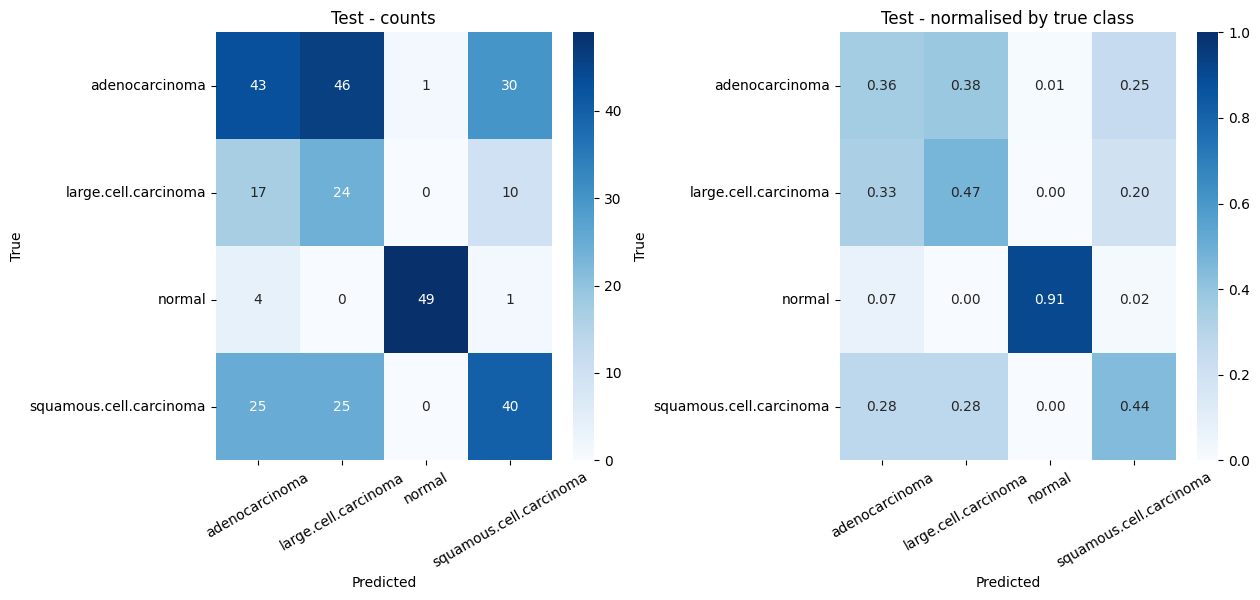

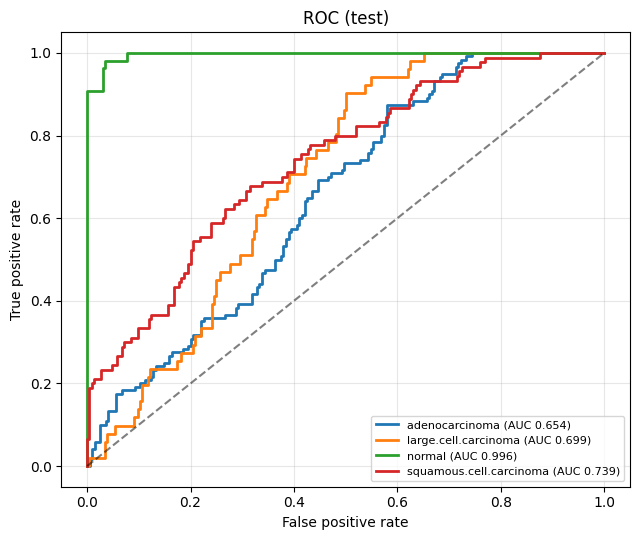

In [13]:
plot_confusion(res["val"][1], res["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
plot_roc(ytest, probtest, CLASS_NAMES)

## Notes
- Plain training by default; set `USE_AUGMENTATION` / `USE_CLASS_WEIGHTS` at the top to change it.
- `VARIANT` XXS / XS / S selects the model size (Table 1). XXS is the default.
- Images are decoded and resized once, kept in memory as uint8 and fed straight to the model, so there are no dataloader workers to crash.
- Best weights: `best_edgevit.pt`; figures are saved as PNGs in the working directory.
- Only about 600 training images, so results move noticeably between seeds; consider several seeds and report mean +/- std.
- Precision / recall / F1 in the curves are **macro** averages over the 4 classes.